# TEモードとベッセル関数
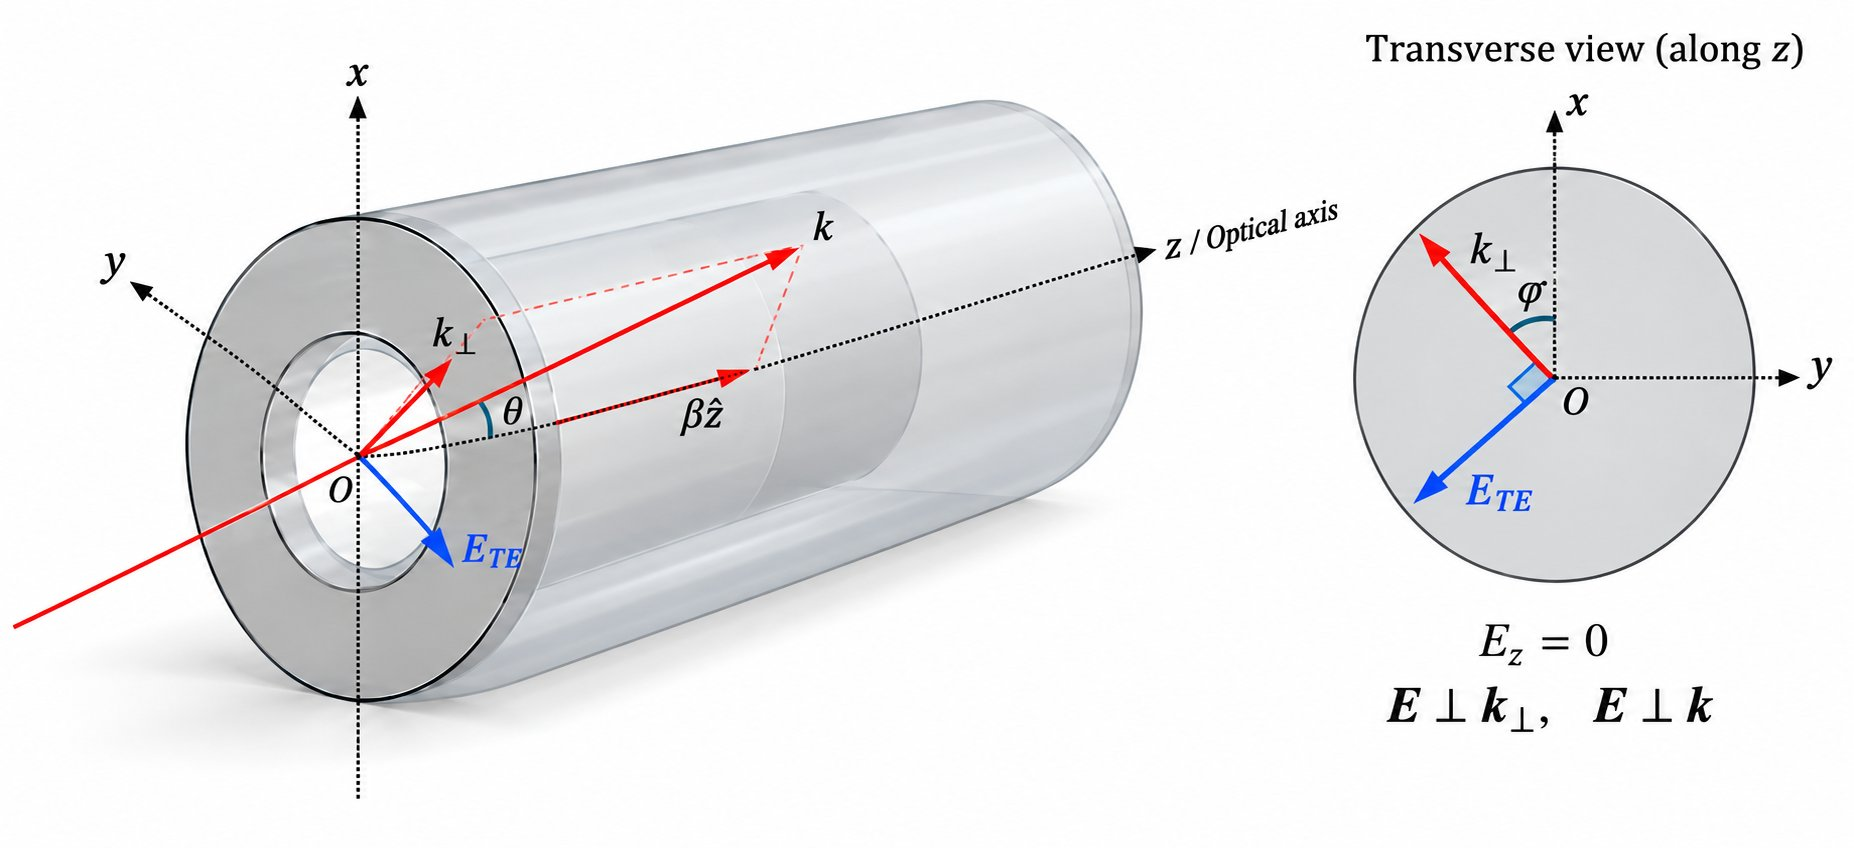


説明、図、実行コードをこの1つのノートブックにまとめた。コードは上から順に実行し、値を変更した後に Shift+Enter で再実行できる。


## 1. 座標系と波数ベクトル

円筒座標を

$$
(r,\phi,z)
$$

とする。ここで、

- $z$：導波路の軸方向
- $r$：軸からの距離
- $\phi$：横断面内の方位角

である。

一様なコア内の各平面波成分について、波数ベクトルを軸方向成分と横方向成分に分けると、

$$
\mathbf{k}=\mathbf{k}_\perp+\beta \hat z
$$

と書ける。円筒対称性を考える場合、横波数の大きさを $k_r$ と書き、

$$
k_r=nk_0\sin\theta,\qquad
\beta=nk_0\cos\theta
$$

とおける。ここで $\theta$ は、波数ベクトル $\mathbf{k}$ と $z$ 軸のなす角である。したがって $\theta$ は「波が導波路の軸に対してどれだけ傾いているか」を表す。


In [1]:
# グラフを表示するには、このセルから実行してください。
import numpy as np
import matplotlib.pyplot as plt

# SciPyを使わず、角度平均によりJ0、J1を数値計算する。
# J0の積分表示: https://dlmf.nist.gov/10.9#E1
# J1 = -J0の微分: https://dlmf.nist.gov/10.6#E3
def j0(x):
    x = np.asarray(x, dtype=float)[..., None]
    n = max(256, int(4*np.max(np.abs(x))) + 32)
    psi = np.linspace(0, 2*np.pi, n, endpoint=False)
    return np.cos(x*np.cos(psi)).mean(axis=-1)

def j1(x):
    x = np.asarray(x, dtype=float)[..., None]
    n = max(256, int(4*np.max(np.abs(x))) + 32)
    psi = np.linspace(0, 2*np.pi, n, endpoint=False)
    return (np.cos(psi)*np.sin(x*np.cos(psi))).mean(axis=-1)

k_r = 1.0     # 横波数：値を変えてみてください。
r_max = 10.0  # グラフに表示する半径の範囲
r = np.linspace(0, r_max, 500)


## 2. TEモードの意味

TEモードとは、軸方向の電場成分が0であるモード、すなわち

$$
E_z=0
$$

を満たすモードである。したがって、導波路内の電場はファイバーの横断面に平行である。
また、

$$
\mathbf{k}=\mathbf{k}_\perp+\beta \hat z
$$

であるため、一様な媒質内の各平面波成分について、$\mathbf{k} \cdot \mathbf{E} = \mathbf{k}_\perp \cdot \mathbf{E} + \beta \hat z  \cdot \mathbf{E} = \mathbf{k}_\perp \cdot \mathbf{E} = 0$

となる。つまり、$\mathbf{E}$ の方向は、$\mathbf{k}$ と $\mathbf{k}_\perp$ が張る平面に垂直である。

$$
\mathbf{k}_\perp = k_r \hat {\mathbf {r}}
$$

とすれば、電場の方向は $\hat{\boldsymbol\phi}$ 方向になる。

ここでの偏光方向の説明は、各平面波成分についてのものである。複数の成分を重ね合わせたモードの電場は、第6節で考える。


## 3. 「反射する平面波の重ね合わせ」から得られる直観
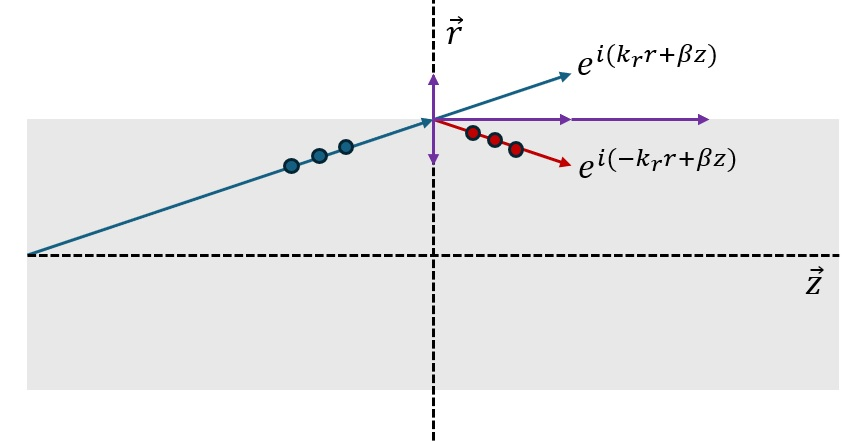

導波路内のモードは、共通の軸方向成分 $\beta$ を持ち、横方向にはそれぞれ異なる方位角の方向に進む平面波成分の重ね合わせとして、直観的に理解できる。1つの成分だけを見ると、例えば

$$
\mathbf{k}=k_r\hat r+\beta \hat z
$$

と書ける。一様な媒質内の平面波では、

$$
\mathbf{E}\cdot \mathbf{k}=0
$$

であるため、電場は $\mathbf{k}$ に垂直でなければならない。円筒座標で直観的に考えると、横方向の電場として $\hat\phi$ 方向を選べば、$\hat r$ にも $\hat z$ にも直交するため、TEの偏光を思い描きやすい。

図のように1つの横方向について反射を考えると、その方向の波数成分は

$$
k_r\rightarrow -k_r
$$

となるが、$\beta$ は変わらない。元の図の記号を使い、選んだ1つの半径方向について2つの成分を比較しよう。2つの成分の振幅を等しくし、相対位相差を省略すると、

$$
e^{i(k_r r+\beta z)}+e^{i(-k_r r+\beta z)}
=
2\cos(k_r r)e^{i\beta z}
$$

のように、$\pm k_r$ 成分の重ね合わせから横方向の定在波構造が生じる。以下の平均は大きさそのものではなく、符号を持つ2つの成分 $+k_r$、$-k_r$ の平均を表す。この意味で、

$$
\langle k_r\rangle=0,\qquad k_r\neq 0
$$

である。つまり、**平均すると横方向には流れないが、横方向の空間スケール自体は残り、その結果として横断面のモード構造が形成される**。

ここでの $\cos(k_r r)$ は、**1つの方向から見た1次元の例**である。
まだ横断面全体にわたる円筒波の解を意味するものではない。
この重ね合わせは、$H_z$ のようなスカラー場成分の空間依存性を説明していると考えればよい。

**ここで、この1つの方向を横断面内で回転させ、すべての方位角からの寄与を足し合わせてみよう。**
その際、各波の位相に入るのは単なる距離 $r$ ではなく、観測点の位置をその波の進行方向に射影した距離である。
次の節では、この過程からベッセル関数が現れることを確かめる。


## 4. 円筒対称性とベッセル関数の登場

前の節のコサイン定在波は、互いに反対方向へ進む2つの平面波を足し合わせたものである。
ここで、構成する平面波の進行方向をすべての方位角に広げる。
$\phi$ は**観測点の方位角**、$\psi$ は**構成する平面波の横方向の進行角度**である。
観測点の位置を $\psi$ 方向に射影した距離は $r\cos(\phi-\psi)$ となる。

円筒座標系において、方位角 $\psi$ の方向を向く横波数ベクトルを持つ平面波成分は、観測点 $(r,\phi)$ で

$$
e^{i k_r r\cos(\phi-\psi)}
$$

という位相因子を与える。共通の軸方向因子は、ここでは省略する。これをすべての方位角について等しい重みで重ね合わせると、

$$
\int_0^{2\pi} e^{i k_r r\cos(\phi-\psi)}\,d\psi
$$

となる。

ベッセル関数の積分表示

$$
J_0(k_r r)
=
\frac{1}{2\pi}
\int_0^{2\pi}
e^{i k_r r\cos(\phi-\psi)}\,d\psi
$$

から、

$$
\boxed{
\int_0^{2\pi}
e^{i k_r r\cos(\phi-\psi)}\,d\psi
=
2\pi J_0(k_r r)
}
$$

を得る。反対方向の平面波を対にすると、虚部が打ち消し合い、前の節のコサイン項が残る。
したがって、この積分は**向きを変えた平面定在波を一様に重ね合わせること**につながる。
すでに円対称である $\cos(k_r r)$ を単に回転させるという意味ではない。

このように、**円筒対称な平面波の重ね合わせから $J_0$ が自然に現れる**。
観測点を $\phi=0$ の方向に置くと、元のコサイン表示でも同じ結果を書ける。

$$
\frac{1}{2\pi} \int_0^{2\pi}
\cos\!\left[k_r r\cos(-\psi)\right]\,d\psi =J_0(k_r r)
$$

さらに、方位角モード数 $l$ を持つ成分を作るには、各平面波成分に方位角 $\psi$ に依存する位相の重み

$$
e^{il\psi}
$$

を掛けて重ね合わせればよい。その結果、

$$
\boxed{
\int_0^{2\pi}
e^{il\psi}
e^{i k_r r\cos(\phi-\psi)}
\,d\psi
=
2\pi i^l J_l(k_r r)e^{il\phi}
}
$$

となる。これは Jacobi–Anger 展開

$$
e^{iz\cos\theta}
=
\sum_{m=-\infty}^{\infty}
i^m J_m(z)e^{im\theta}
$$

から直接得られる結果であり、**平面波の重ね合わせが円筒波 $J_l(k_r r)e^{il\phi}$ を作る**ことを示している。

この節の積分は、スカラーの空間関数についての関係である。これを電場ベクトル全体にそのまま適用するのではなく、次の節では $H_z$ の分布と結び付ける。

出典：[NIST DLMF、ベッセルの積分表示 (10.9.1)](https://dlmf.nist.gov/10.9#E1)、[Jacobi–Anger 展開](https://dlmf.nist.gov/10.12)。


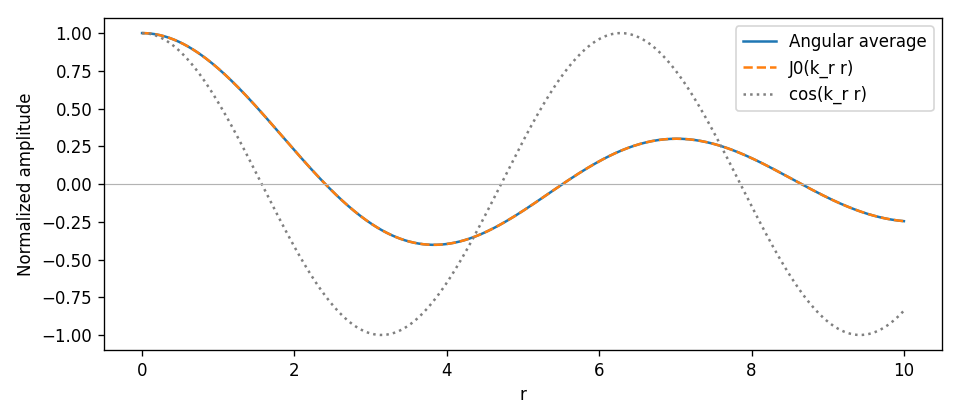

In [2]:
# 第4節：すべての方向のコサイン平均とJ0を比較する。
N = 128  # 方向の数：4、16、128に変えてみてください。
psi = np.linspace(0, 2*np.pi, N, endpoint=False)
mean_wave = np.cos(k_r * r[:, None] * np.cos(psi)).mean(axis=1)

plt.figure(figsize=(8, 3.5))
plt.plot(r, mean_wave, label="Angular average")
plt.plot(r, j0(k_r*r), "--", label="J0(k_r r)")
plt.plot(r, np.cos(k_r*r), ":", color="0.5", label="cos(k_r r)")
plt.axhline(0, color="0.7", linewidth=0.7)
plt.xlabel("r")
plt.ylabel("Normalized amplitude")
plt.legend()
plt.tight_layout()
plt.show()


## 5. TEモードのベッセル関数表示

円形導波路のTEモードでは $E_z=0$ であり、縦方向の磁場 $H_z$ が基本となる。円形導波路で用いられる縦方向磁場のベッセル関数表示は、

$$
H_z(r,\phi,z)
=
H_0\,J_l(k_c r)\,[A\cos(l\phi)+B\sin(l\phi)]\,e^{-i\beta z}
$$

という形で書ける。複素数表示を用いれば、

$$
H_z(r,\phi,z)\propto J_l(k_c r)e^{il\phi}e^{-i\beta z}
$$

と書いてもよい。以下では原文と同様に軸方向因子を $e^{-i\beta z}$ と表記し、横方向の空間分布に注目する。ここで $k_c$ は横方向の固有波数であり、境界条件によって離散的な値に定まる。

この一般式を、光ファイバーのすべての $l$ に対する純粋なTEモードと解釈してはいけない。
ここでは光ファイバーの**軸対称な $TE_{0m}$ モード**、すなわち $l=0$ の場合に注目する。
許容される波数は、コアと外部媒質の境界で $H_z$ と $E_\phi$ を連続につなぐことにより定まる。
境界方程式の詳しい計算は、ここでは扱わない。

なお、原文にあった

$$
J_l'(k_c a)=0
$$

と「支配モードは $TE_{11}$」という説明は、**完全導体の壁を持つ円形導波路**に当てはまる。
この条件を光ファイバーにそのまま適用することはできない。

出典：[UT Austin、誘電体導波路のTEの場と境界条件、式 (1386)–(1396)](https://farside.ph.utexas.edu/teaching/jk1/Electromagnetism/node118.html#:~:text=For%20a%20TE%20mode)。


## 6. $TE_{0m}$ で $E_\phi\propto J_1$ が現れる理由

軸対称なTEモードでは $l=0$ であるため、縦方向磁場は

$$
H_z(r,z)\propto J_0(k_c r)e^{-i\beta z}
$$

となる。

TEモードの横電場成分は、Maxwell方程式により $H_z$ の半径方向の微分から定まり、特に軸対称の場合は

$$
E_\phi \propto -\frac{\partial H_z}{\partial r}
$$

となる。したがって、

$$
E_\phi
\propto
-\frac{\partial}{\partial r}J_0(k_c r)
$$

である。ここで、ベッセル関数の微分公式

$$
\frac{dJ_0(x)}{dx}=-J_1(x)
$$

を使うと、

$$
E_\phi\propto J_1(k_c r)
$$

を得る。つまり $TE_{0m}$ では、縦方向磁場が $J_0$ 型であっても、横電場 $E_\phi$ は $J_1$ 型になる。

ここでの比例関係は、共通の係数と位相因子を省略し、**半径方向の形状**を比較したものである。
$E_\phi$ に $J_1$ が現れても、方位角モード数が $l=1$ に変わるわけではない。

出典：[NIST DLMF、微分公式 (10.6.3)](https://dlmf.nist.gov/10.6#E3)。


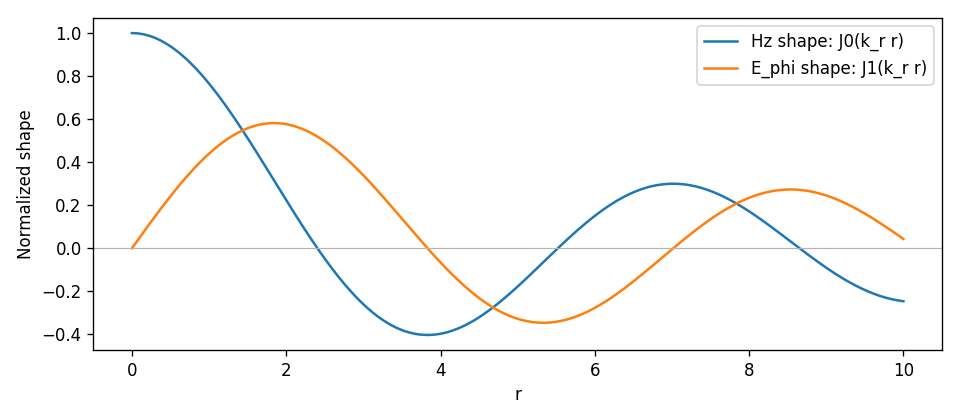

In [3]:
# 第6節：共通の係数を除いたHzとE_phiの空間分布を比較する。
plt.figure(figsize=(8, 3.5))
plt.plot(r, j0(k_r*r), label="Hz shape: J0(k_r r)")
plt.plot(r, j1(k_r*r), label="E_phi shape: J1(k_r r)")
plt.axhline(0, color="0.7", linewidth=0.7)
plt.xlabel("r")
plt.ylabel("Normalized shape")
plt.legend()
plt.tight_layout()
plt.show()


## 7. $l$ の意味

縦方向磁場の複素数表示

$$
H_z(r,\phi,z)\propto J_l(k_r r)e^{il\phi}e^{-i\beta z}
$$

において、$l$ は**方位角モード数**である。

- $l=0$ では $e^{i0\phi}=1$ となるため、このスカラー場成分は方位角 $\phi$ に依存しない。
- $l=1$ では $e^{i\phi}$ となり、$\phi$ を $2\pi$ だけ回すと、複素位相が $2\pi$ 変化する。
- $l=2$ では $e^{i2\phi}$ となり、1周で複素位相が $4\pi$ 変化する。

この意味では、複素数表示の $l$ は「位相の巻き数」に対応するように見える。しかし、円形導波路の一般的なTE/TMモードでは、しばしば

$$
\cos(l\phi),\qquad \sin(l\phi)
$$

という実関数表示を用いるため、最も誤解の少ない呼び方は**方位角モード数**である。つまり $l$ は**偏光方向**を表す量ではなく、**横断面内の角度依存性の次数**を表す量である。

軸対称なTEモードの電場は $\hat{\boldsymbol\phi}$ 方向を向く。成分 $E_\phi(r)$ が方位角に依存しなくても、ベクトルの向きは円周に沿って変わる。


## 8. まとめ

以上をまとめると、ここで扱ったTEモードは

$$
E_z=0,\qquad H_z\neq 0
$$

を満たすモードであり、横方向の構造は平面波成分の重ね合わせとして理解できる。その円筒対称な重ね合わせの結果、半径方向の依存性はベッセル関数 $J_l$ で表される。特に、すべての方位角を等しい重みで重ね合わせると $J_0$ が現れ、方位角に位相の重み $e^{il\psi}$ を与えると $J_l(k_r r)e^{il\phi}$ が現れる。軸対称なTEモードでは縦方向磁場 $H_z$ が基本となり、$TE_{0m}$ では $H_z\propto J_0$、そこから導かれる横電場は

$$
E_\phi\propto J_1
$$

となる。したがって $l$ は偏光を表すものではなく、**モードの方位角依存性を表す指標**である。
